# 模型 6：BiLSTM + Attention

**负责人：** 6 号　**阶段：** 3 模型

token 序列 → BiLSTM + 加性注意力。

## 任务
- [x] 使用 FastText token 序列（按折版本）
- [x] 1–2 层 BiLSTM，hidden 128，处理 padding mask
- [x] 使用 Member 4 的 `src.training` 训练模板
- [x] 挑几条推文画注意力热力图
- [x] 每次实验先用 `new_run_id()`

## 产出
- `results/m6_bilstm.csv`
- 用 `save_preds` 保存 OOF 和测试集概率
- `figures/m6_attention_*.png`

第一版使用 Member 2 的 FastText token 序列。Member 5 的冻结 SBERT token 序列可在 11/8 后直接替换，无需改模型结构。

In [1]:
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError("找不到仓库根目录")
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR, LABELS, SEED, N_FOLDS
from src.data import load_clean, load_splits
from src.evaluate import evaluate, new_run_id, save_result, plot_confusion
from src.cache import load_embedding, save_preds
from src.training import seed_everything, TrainConfig, fit_model, predict_proba

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt

seed_everything(SEED)
print("仓库根目录:", ROOT)

仓库根目录: d:\bigdata\PolyU_DSAI4205_Group_Project


In [2]:
clean = load_clean()
splits = load_splits(clean=clean)
label_of = dict(zip(clean["id"], clean["label"]))
dev = splits[splits["split"] == "train"].reset_index(drop=True)
test = splits[splits["split"] == "test"].reset_index(drop=True)
y_dev = dev["id"].map(label_of).to_numpy()
y_test = test["id"].map(label_of).to_numpy()
print(f"Train {len(dev)}, Test {len(test)}")

Train 1222, Test 303


In [3]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.W = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h, mask):
        # h: (B, L, H), mask: (B, L) bool, True = real token
        score = self.v(torch.tanh(self.W(h))).squeeze(-1)          # (B, L)
        score = score.masked_fill(~mask, float("-inf"))
        # handle empty sequences
        empty = ~mask.any(dim=1)
        score = score.masked_fill(empty.unsqueeze(1), 0.0)
        alpha = torch.softmax(score, dim=1)
        alpha = alpha.masked_fill(empty.unsqueeze(1), 0.0)
        context = torch.bmm(alpha.unsqueeze(1), h).squeeze(1)      # (B, H)
        return context, alpha


class BiLSTMAttention(nn.Module):
    def __init__(self, input_dim=100, hidden=128, n_layers=2, n_classes=3, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_dim, hidden, num_layers=n_layers,
            bidirectional=True, batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.attn = AdditiveAttention(hidden * 2)
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden * 2, n_classes),
        )

    def forward(self, x, mask=None):
        if mask is None:
            mask = torch.ones(x.size(0), x.size(1), dtype=torch.bool, device=x.device)

        lengths = mask.sum(dim=1).clamp(min=1).cpu()               # clamp for packing
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(out, batch_first=True)          # (B, L_batch, 2H)

        # Truncate mask to the actual length of this batch (fixes 31 vs 30 error)
        L = h.size(1)
        mask = mask[:, :L]

        context, alpha = self.attn(h, mask)
        logits = self.fc(context)
        return logits

In [4]:
def load_fold_data(fold):
    train_ids = dev.loc[dev["fold"] != fold, "id"].to_numpy()
    val_ids = dev.loc[dev["fold"] == fold, "id"].to_numpy()
    seq_tr = load_embedding(f"fasttext_tok_fold{fold}", ids=train_ids)
    mask_tr = load_embedding(f"fasttext_tok_fold{fold}_mask", ids=train_ids)
    seq_va = load_embedding(f"fasttext_tok_fold{fold}", ids=val_ids)
    mask_va = load_embedding(f"fasttext_tok_fold{fold}_mask", ids=val_ids)
    y_tr = y_dev[dev["fold"] != fold]
    y_va = y_dev[dev["fold"] == fold]
    return seq_tr, mask_tr, y_tr, seq_va, mask_va, y_va

In [5]:
# Cross-validation with Member 4 training template
oof_proba = np.zeros((len(dev), 3))
config = TrainConfig(epochs=20, patience=5, batch_size=32, lr=1e-3, device="cpu")

for k in range(N_FOLDS):
    print(f"Fold {k} ...")
    seq_tr, mask_tr, y_tr, seq_va, mask_va, y_va = load_fold_data(k)

    seed_everything(SEED)
    model = BiLSTMAttention()
    fit_model(
        model, seq_tr, y_tr, seq_va, y_va,
        train_mask=mask_tr, valid_mask=mask_va,
        config=config,
    )
    val_proba = predict_proba(model, seq_va, mask_va, device=config.device)
    in_val = (dev["fold"] == k).to_numpy()
    oof_proba[in_val] = val_proba

oof_pred = oof_proba.argmax(axis=1)
run_id = new_run_id("bilstm", "fasttext_tok")
row = evaluate(
    y_dev, oof_pred,
    run_id=run_id, model="bilstm", embedding="fasttext_tok",
    split="cv", params={"hidden": 128, "layers": 2, "epochs": 20},
)
save_result(row, "m6_bilstm")
print("CV Macro-F1:", row["macro_f1"])

Fold 0 ...
Fold 1 ...
Fold 2 ...
Fold 3 ...
Fold 4 ...
CV Macro-F1: 0.5499292495760678


Test Macro-F1: 0.4945534455240847


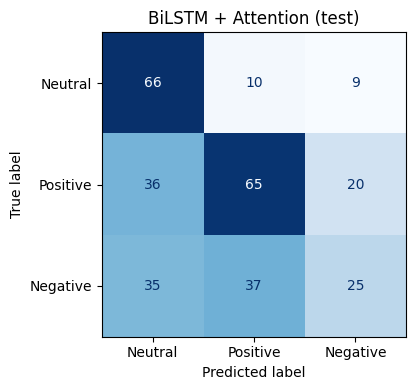

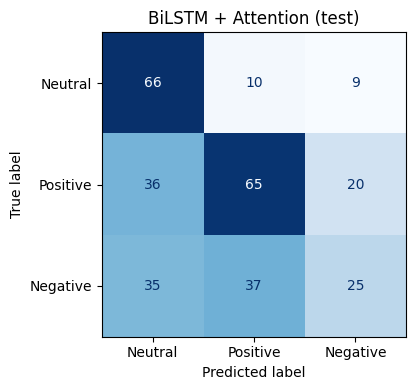

In [6]:
# Final model on full training set
seq_full_tr = load_embedding("fasttext_tok_full", ids=dev["id"].to_numpy())
mask_full_tr = load_embedding("fasttext_tok_full_mask", ids=dev["id"].to_numpy())
seq_te = load_embedding("fasttext_tok_full", ids=test["id"].to_numpy())
mask_te = load_embedding("fasttext_tok_full_mask", ids=test["id"].to_numpy())

seed_everything(SEED)
final_model = BiLSTMAttention()
fit_model(
    final_model, seq_full_tr, y_dev,
    train_mask=mask_full_tr,
    config=TrainConfig(epochs=15, batch_size=32, lr=1e-3, device="cpu"),
)

test_proba = predict_proba(final_model, seq_te, mask_te, device="cpu")
test_pred = test_proba.argmax(axis=1)
test_row = evaluate(
    y_test, test_pred,
    run_id=run_id, model="bilstm", embedding="fasttext_tok",
    split="test", params={"hidden": 128, "layers": 2, "epochs": 15},
)
save_result(test_row, "m6_bilstm")
print("Test Macro-F1:", test_row["macro_f1"])

save_preds(
    run_id,
    oof_ids=dev["id"].to_numpy(), oof_proba=oof_proba,
    test_ids=test["id"].to_numpy(), test_proba=test_proba,
    classes=[0, 1, 2],
)

plot_confusion(
    y_test, test_pred, "BiLSTM + Attention (test)",
    save_as=FIGURES_DIR / "m6_bilstm_confusion.png",
)

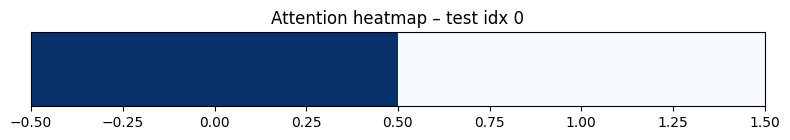

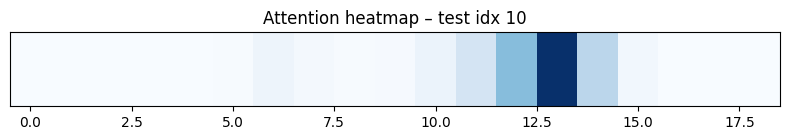

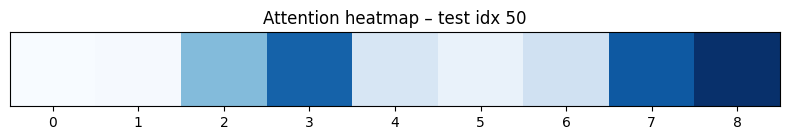

In [7]:
# Attention heatmap examples (optional visualization)
final_model.eval()
examples = [0, 10, 50]
with torch.no_grad():
    for idx in examples:
        x = torch.tensor(seq_te[idx:idx+1], dtype=torch.float32)
        mask = torch.tensor(mask_te[idx:idx+1], dtype=torch.bool)
        # run forward to get attention (re-implement a small hook-style call)
        lengths = mask.sum(dim=1).clamp(min=1).cpu()
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = final_model.lstm(packed)
        h, _ = pad_packed_sequence(out, batch_first=True)
        L = h.size(1)
        mask_trunc = mask[:, :L]
        _, alpha = final_model.attn(h, mask_trunc)
        alpha = alpha.cpu().numpy()[0]
        length = int(mask_trunc.sum())
        if length == 0:
            continue
        fig, ax = plt.subplots(figsize=(8, 1.5))
        ax.imshow(alpha[:length].reshape(1, -1), cmap="Blues", aspect="auto")
        ax.set_title(f"Attention heatmap – test idx {idx}")
        ax.set_yticks([])
        fig.tight_layout()
        fig.savefig(FIGURES_DIR / f"m6_attention_{idx}.png", dpi=200)
        plt.show()